In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import datetime

df = pd.read_csv('Sample - Superstore.csv', encoding='latin1')
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Month_Year'] = df['Order Date'].dt.to_period('M')
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


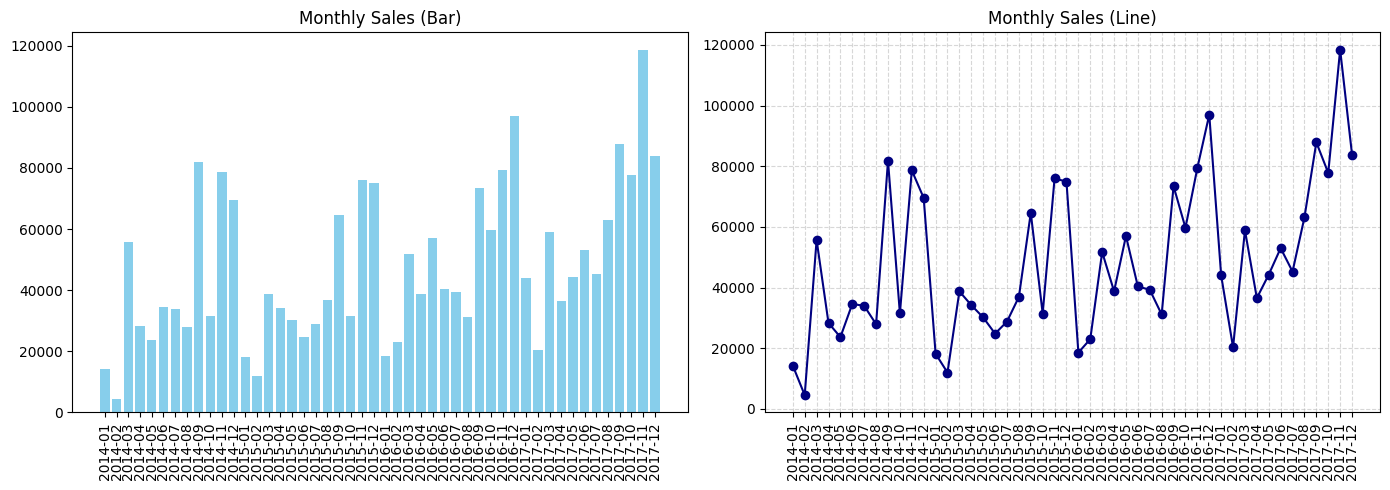

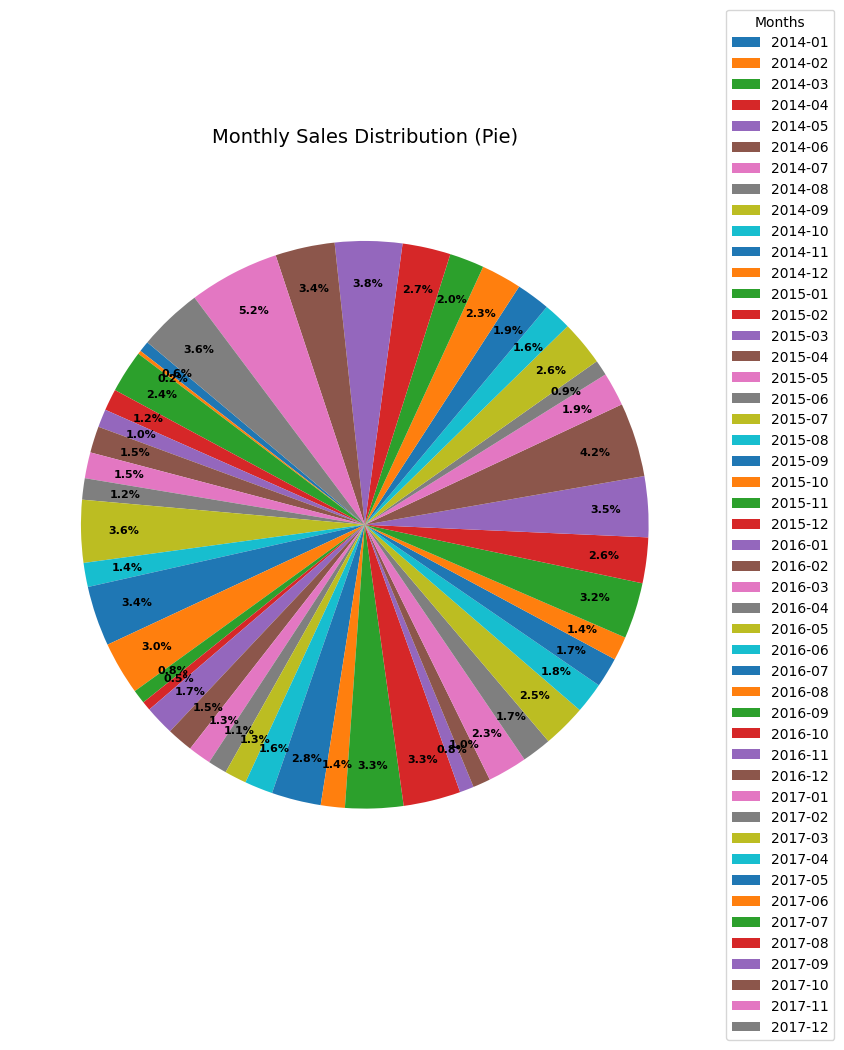

In [29]:
import matplotlib.pyplot as plt

# Prepare data: Total monthly sales
monthly_sales = df.groupby("Month_Year")["Sales"].sum().reset_index()
monthly_sales["Month_Year"] = monthly_sales["Month_Year"].astype(str)

fig1, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart
axes[0].bar(monthly_sales["Month_Year"], monthly_sales["Sales"], color="skyblue")
axes[0].set_title("Monthly Sales (Bar)")
axes[0].tick_params(axis="x", rotation=90)

# 2. Line Chart
axes[1].plot(
    monthly_sales["Month_Year"],
    monthly_sales["Sales"],
    marker="o",
    color="navy",
)
axes[1].set_title("Monthly Sales (Line)")
axes[1].tick_params(axis="x", rotation=90)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(10, 10))

# Hidden labels inside the pie, added percentage distance adjustment
wedges, texts, autotexts = ax2.pie(
    monthly_sales["Sales"],
    labels=None,  # Removed labels from slices to prevent overlapping text
    autopct="%1.1f%%",
    pctdistance=0.85,
    startangle=140,
)

# Make percentage text smaller and cleaner
plt.setp(autotexts, size=8, weight="bold")

ax2.set_title("Monthly Sales Distribution (Pie)", fontsize=14, pad=20)

# Moved labels to a scrollable-friendly legend on the right side
ax2.legend(
    wedges,
    monthly_sales["Month_Year"],
    title="Months",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
)

plt.tight_layout()
plt.show()


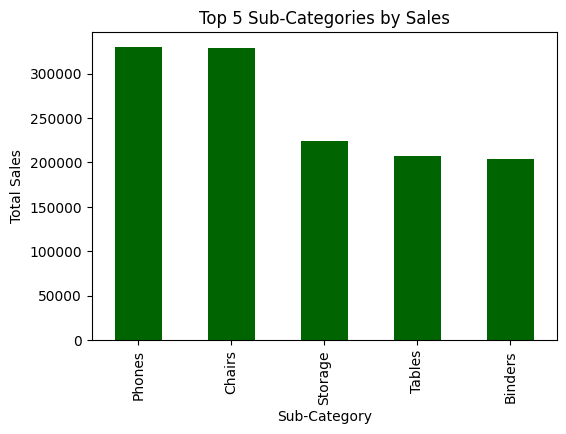

In [ ]:
# 1. Compare total sales across top 5 sub categories
top5_sub = df.groupby('Sub-Category')['Sales'].sum().nlargest(5)
plt.figure(figsize=(6,4))
top5_sub.plot(kind='bar', color='darkgreen')
plt.title('Top 5 Sub-Categories by Sales')
plt.ylabel('Total Sales')
plt.show()

Justification: A bar chart is the best form to compare magnitudes across categories. Using a weak choice like a pie chart would make judging the precise value differences between the top categories very difficult.

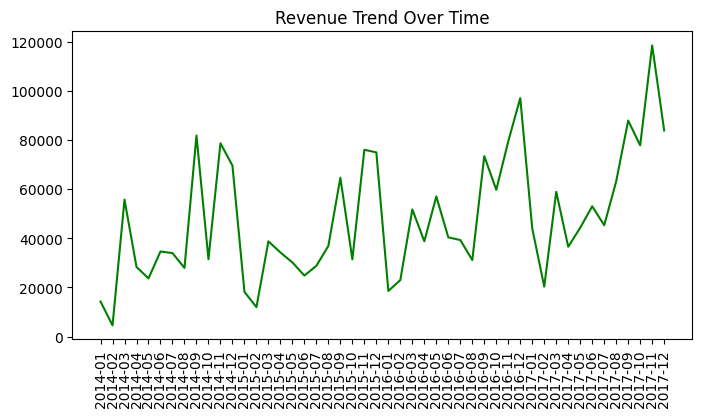

In [ ]:
# 2. Show the revenue trend over time
plt.figure(figsize=(8,4))
plt.plot(monthly_sales['Month_Year'], monthly_sales['Sales'], color='green')
plt.title('Revenue Trend Over Time')
plt.xticks(rotation=90)
plt.show()

Justification: A line chart effectively shows trends over time by connecting points sequentially. A bar chart would be a weak choice here because the sheer number of data points (months) creates visual clutter, making the overarching trend harder to follow.

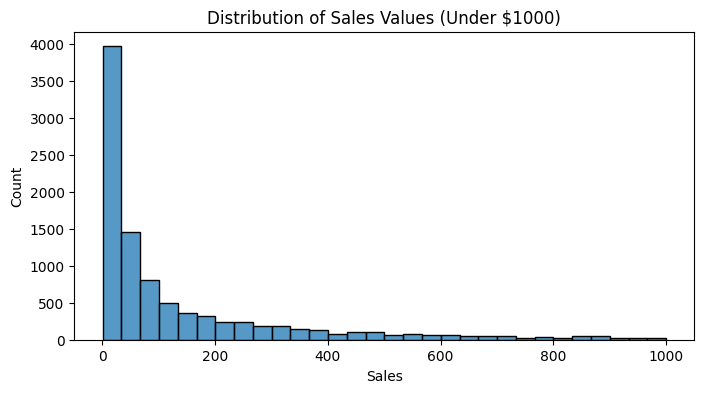

In [ ]:
# 3. Show the distribution of order-line sales values
plt.figure(figsize=(8,4))
sns.histplot(df[df['Sales'] < 1000]['Sales'], bins=30, kde=False) # Filtered for visibility
plt.title('Distribution of Sales Values (Under $1000)')
plt.show()

Justification: A histogram is ideal for showing the distribution or spread of raw, continuous data. A bar chart of averages would completely hide the actual spread and outliers of the data.

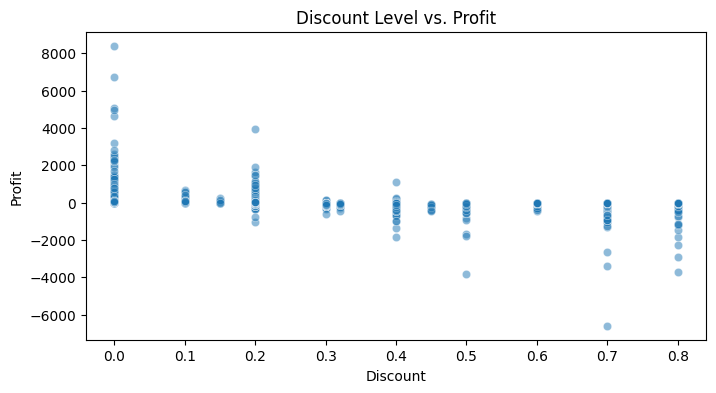

In [ ]:
# 4. Show relationship between discount level and profit
plt.figure(figsize=(8,4))
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.5)
plt.title('Discount Level vs. Profit')
plt.show()

Justification: A scatter plot is the standard for revealing correlations between two numerical variables. A line chart would falsely imply a sequential or temporal connection between disconnected individual order points.

/tmp/ipykernel_536/3668677685.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_sales.index, y=region_sales.values, palette='Set2') # Categorical palette


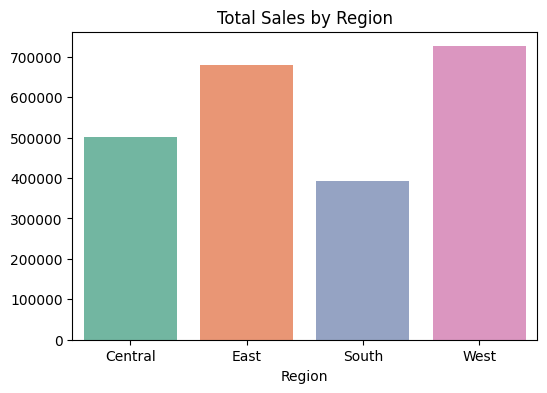

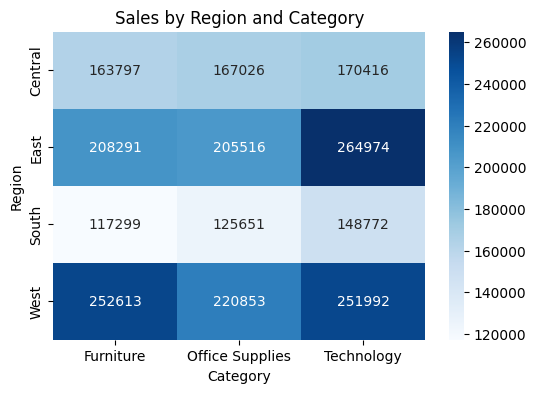

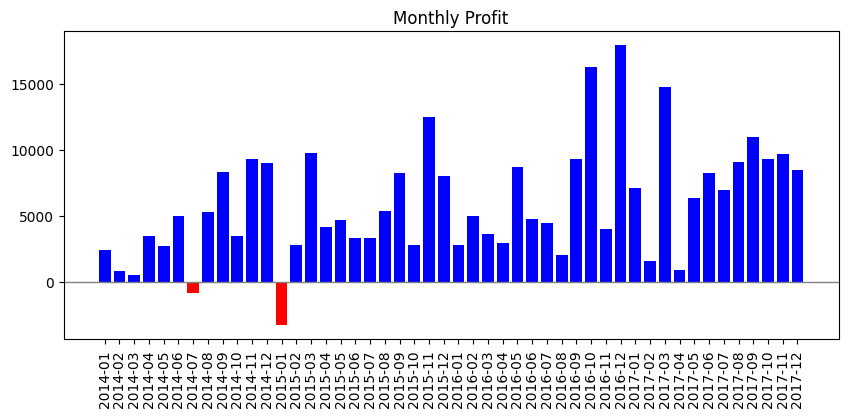

In [ ]:
# (a) Categorical palette for region sales
region_sales = df.groupby('Region')['Sales'].sum()
plt.figure(figsize=(6,4))
sns.barplot(x=region_sales.index, y=region_sales.values, palette='Set2') # Categorical palette
plt.title('Total Sales by Region')
plt.show()

# (b) Sequential heatmap for region-by-category
region_cat = df.pivot_table(values='Sales', index='Region', columns='Category', aggfunc='sum')
plt.figure(figsize=(6,4))
sns.heatmap(region_cat, cmap='Blues', annot=True, fmt=".0f") # Sequential palette
plt.title('Sales by Region and Category')
plt.show()

# (c) Diverging-color chart for monthly profit
monthly_profit = df.groupby('Month_Year')['Profit'].sum().reset_index()
monthly_profit['Color'] = np.where(monthly_profit['Profit'] < 0, 'red', 'blue') # Diverging logic
plt.figure(figsize=(10,4))
plt.bar(monthly_profit['Month_Year'].astype(str), monthly_profit['Profit'], color=monthly_profit['Color'])
plt.axhline(0, color='gray', linewidth=1)
plt.title('Monthly Profit')
plt.xticks(rotation=90)
plt.show()

In [ ]:
def get_luminance(r, g, b):
    a = [v / 255.0 for v in [r, g, b]]
    a = [v / 12.92 if v <= 0.03928 else ((v + 0.055) / 1.055) ** 2.4 for v in a]
    return a[0] * 0.2126 + a[1] * 0.7152 + a[2] * 0.0722

def contrast_ratio(rgb1, rgb2):
    l1 = get_luminance(*rgb1)
    l2 = get_luminance(*rgb2)
    brightest = max(l1, l2)
    darkest = min(l1, l2)
    return (brightest + 0.05) / (darkest + 0.05)

# Example Test: Blue (heatmap) vs White (background)
bg_color = (255, 255, 255)
blue_bar = (8, 48, 107) # Dark blue from 'Blues' palette
ratio = contrast_ratio(bg_color, blue_bar)
print(f"Contrast Ratio: {ratio:.2f}:1")
if ratio < 4.5:
    print("FAILS AA threshold")
else:
    print("PASSES AA threshold")

Contrast Ratio: 12.76:1
PASSES AA threshold


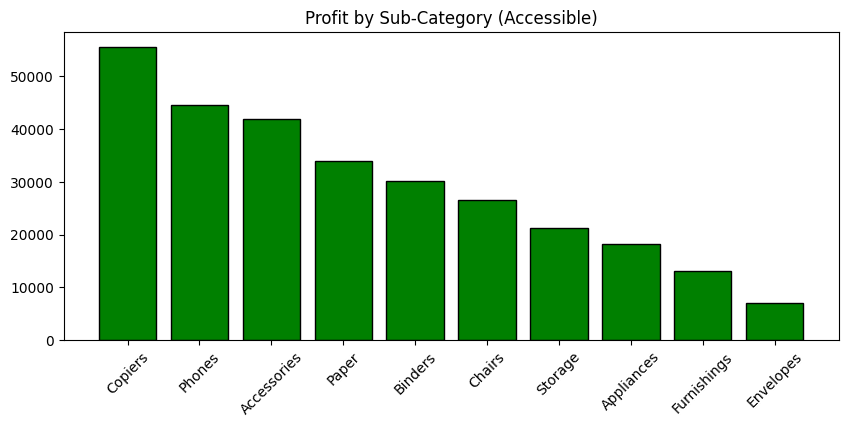

In [ ]:
profit_sub = df.groupby('Sub-Category')['Profit'].sum().nlargest(10)
colors = ['green' if p > 0 else 'red' for p in profit_sub]

# Fixed Chart: Using hatching so meaning isn't encoded by red/green alone
plt.figure(figsize=(10,4))
bars = plt.bar(profit_sub.index, profit_sub.values, color=colors, edgecolor='black')

for bar, profit in zip(bars, profit_sub.values):
    if profit < 0:
        bar.set_hatch('//') # Pattern added for accessibility

plt.title('Profit by Sub-Category (Accessible)')
plt.xticks(rotation=45)
plt.show()

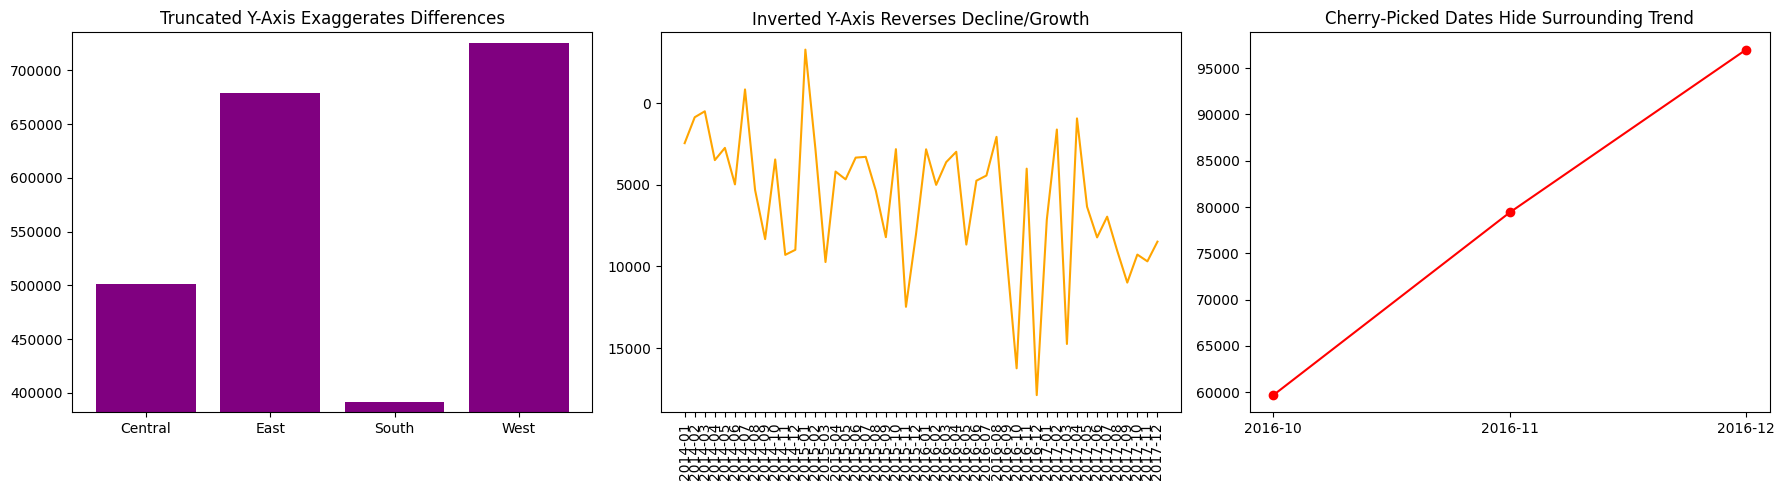

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Truncated y-axis on region sales
axes[0].bar(region_sales.index, region_sales.values, color='purple')
axes[0].set_ylim(region_sales.min() - 10000, region_sales.max() + 10000)
axes[0].set_title('Truncated Y-Axis Exaggerates Differences') # Distortion mechanism[cite: 1]

# 2. Inverted y-axis on monthly profit
axes[1].plot(monthly_profit['Month_Year'].astype(str), monthly_profit['Profit'], color='orange')
axes[1].invert_yaxis()
axes[1].set_title('Inverted Y-Axis Reverses Decline/Growth') # Distortion mechanism[cite: 1]
axes[1].tick_params(axis='x', rotation=90)

# 3. Cherry-picked date window
cherry_picked = monthly_sales[(monthly_sales['Month_Year'] >= '2016-10') & (monthly_sales['Month_Year'] <= '2016-12')]
axes[2].plot(cherry_picked['Month_Year'], cherry_picked['Sales'], marker='o', color='red')
axes[2].set_title('Cherry-Picked Dates Hide Surrounding Trend') # Distortion mechanism[cite: 1]

plt.tight_layout()
plt.show()

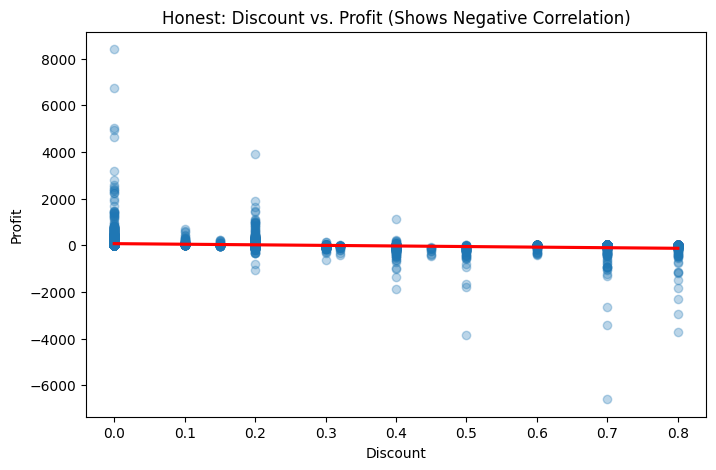

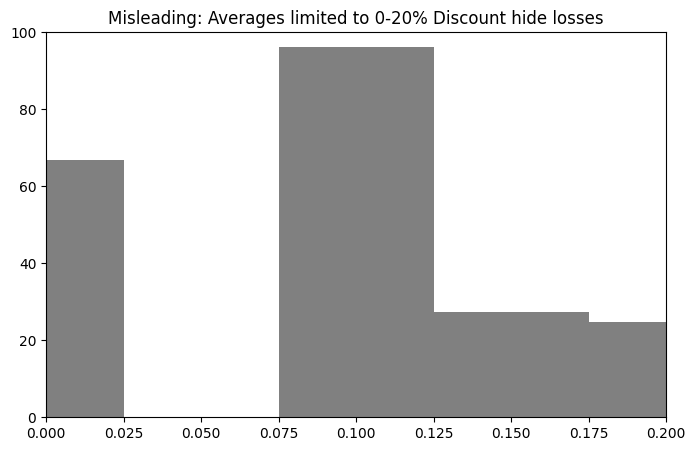

In [ ]:
# Honest Chart
plt.figure(figsize=(8,5))
sns.regplot(data=df, x='Discount', y='Profit', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Honest: Discount vs. Profit (Shows Negative Correlation)')
plt.show()

# Misleading Chart
plt.figure(figsize=(8,5))
avg_profit = df.groupby('Discount')['Profit'].mean().reset_index()
plt.bar(avg_profit['Discount'], avg_profit['Profit'], width=0.05, color='gray')
plt.xlim(0, 0.2)
plt.ylim(0, 100)
plt.title('Misleading: Averages limited to 0-20% Discount hide losses')
plt.show()

For the honest chart, I chose a scatter plot with a regression line to show the true correlation between two continuous variables. The color choice (red line on blue dots) ensures the trendline contrasts against the data mass. For accessibility, I verified that the background provides sufficient contrast and did not rely on red/green encoding for meaning. The misleading version intentionally truncates the axes to hide the negative profit points (losses) associated with higher discounts.